#Load Dataset

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Membaca file dataset yang sudah di-upload ke Colab
df = pd.read_csv('dataset_tugas1_preprocessing.csv')

# Tampilkan 5 baris pertama
df.head()

,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
0,MH001,Iwan,Laki-laki,Teknik Komputer,Aktif,NaN,13-04-2020,NaN
1,MH002,Eka,Perempuan,Teknik Komputer,Lulus,E,2020/12/11,28.0
2,MH003,Iwan,Laki-laki,Teknik Komputer,Aktif,NaN,2021/11/21,23.0
3,MH004,Eka,Perempuan,Teknik Komputer,Aktif,D,2021/08/19,18.0
4,MH005,Joko,Perempuan,Data Science,Aktif,C,2020/01/05,26.0


#Eksplorasi Awal (EDA)

In [18]:
# 1. Cek struktur dan tipe data
print('=== Struktur dan Tipe Data ===')
df.info()

# 2. Tampilkan jumlah nilai hilang per kolom
print('\n=== Jumlah Missing Values per Kolom ===')
print(df.isnull().sum())

# 3. Sajikan statistik deskriptif
print('\n=== Statistik Deskriptif ===')
display(df.describe(include='all'))

=== Struktur dan Tipe Data ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             99 non-null     object 
 1   Nama           99 non-null     object 
 2   Jenis_Kelamin  99 non-null     object 
 3   Prodi          99 non-null     object 
 4   Status         99 non-null     object 
 5   Nilai_Akhir    70 non-null     object 
 6   Tanggal_Ujian  99 non-null     object 
 7   Umur           90 non-null     float64
dtypes: float64(1), object(7)
memory usage: 6.3+ KB

=== Jumlah Missing Values per Kolom ===
ID                0
Nama              0
Jenis_Kelamin     0
Prodi             0
Status            0
Nilai_Akhir      29
Tanggal_Ujian     0
Umur              9
dtype: int64

=== Statistik Deskriptif ===


,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
count,99,99,99,99,99,70,99,90.000000
unique,99,10,2,4,4,5,97,NaN
top,MH001,Eka,Laki-laki,Teknik Komputer,Cuti,C,2020/03/31,NaN
freq,1,15,50,28,29,17,2,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.366667
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.763963
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,26.000000


# Menangani Missing Values

In [19]:
# Imputasi kolom Umur dengan Median
df['Umur'] = df['Umur'].fillna(df['Umur'].median())

# Imputasi kolom Nilai_Akhir dengan Modus (nilai terbanyak)
df['Nilai_Akhir'] = df['Nilai_Akhir'].fillna(df['Nilai_Akhir'].mode()[0])

# Cek kembali apakah masih ada nilai yang hilang
print('=== Jumlah Missing Values Setelah Imputasi ===')
print(df.isnull().sum())

=== Jumlah Missing Values Setelah Imputasi ===
ID               0
Nama             0
Jenis_Kelamin    0
Prodi            0
Status           0
Nilai_Akhir      0
Tanggal_Ujian    0
Umur             0
dtype: int64


# Encoding Label

In [20]:
le = LabelEncoder()
kategorikal_cols = [
    'Nama',
    'Jenis_Kelamin',
    'Prodi',
    'Status',
    'Nilai_Akhir',
]

# Terapkan Label Encoder untuk setiap kolom kategorikal
for col in kategorikal_cols:
  df[col + '_Encoded'] = le.fit_transform(df[col].astype(str))

# Tampilkan beberapa kolom hasil encoding
df[[
    'Nama',
    'Nama_Encoded',
    'Prodi',
    'Prodi_Encoded',
    'Nilai_Akhir',
    'Nilai_Akhir_Encoded',
]].head()

,Nama,Nama_Encoded,Prodi,Prodi_Encoded,Nilai_Akhir,Nilai_Akhir_Encoded
0,Iwan,8,Teknik Komputer,3,C,2
1,Eka,4,Teknik Komputer,3,E,4
2,Iwan,8,Teknik Komputer,3,C,2
3,Eka,4,Teknik Komputer,3,D,3
4,Joko,9,Data Science,0,C,2


# Split Data

In [21]:
# Memisahkan fitur utama dari ID dan Tanggal_Ujian
X = df.drop(columns=['ID', 'Tanggal_Ujian'])

# Membagi data menjadi 80% Train dan 20% Test
X_train, X_test = train_test_split(X, test_size=0.2, random_state=42)

print(f'Ukuran Data Latih (Train Set) : {X_train.shape[0]} baris (80%)')
print(f'Ukuran Data Uji (Test Set)   : {X_test.shape[0]} baris (20%)')

Ukuran Data Latih (Train Set) : 79 baris (80%)
Ukuran Data Uji (Test Set)   : 20 baris (20%)


# Visualisasi

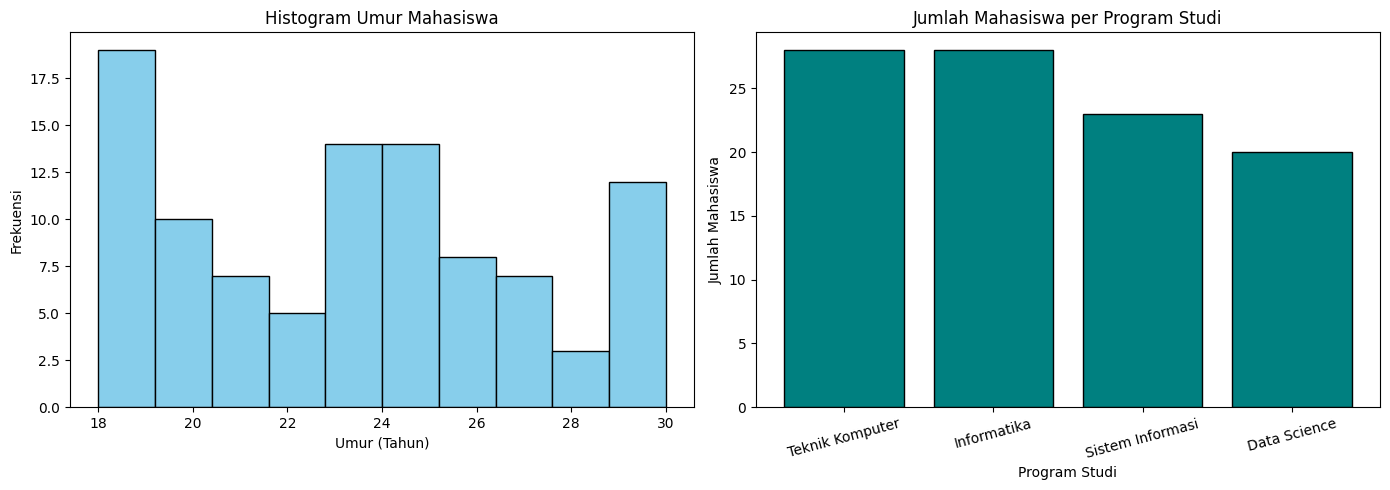

In [22]:
plt.figure(figsize=(14, 5))

# 1. Histogram Umur Mahasiswa
plt.subplot(1, 2, 1)
plt.hist(df['Umur'], bins=10, color='skyblue', edgecolor='black')
plt.title('Histogram Umur Mahasiswa')
plt.xlabel('Umur (Tahun)')
plt.ylabel('Frekuensi')

# 2. Grafik Batang Jumlah Mahasiswa per Prodi
plt.subplot(1, 2, 2)
prodi_counts = df['Prodi'].value_counts()
plt.bar(prodi_counts.index, prodi_counts.values, color='teal', edgecolor='black')
plt.title('Jumlah Mahasiswa per Program Studi')
plt.xlabel('Program Studi')
plt.ylabel('Jumlah Mahasiswa')
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()